In [21]:
from google.colab import files
uploaded = files.upload()

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (1).csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentPerformanceFactors.csv")
df.head()

In [ ]:
print(df.shape)
df.info()
df.isna().sum()

Dataset: https://www.kaggle.com/datasets/lainguyn123/student-performance-factors
Rows and columns: (6607, 20)

=== 1. STATISTICAL SUMMARY ===


,Hours_Studied,Attendance,Exam_Score
count,6607.00,6607.00,6607.00
mean,19.98,79.98,67.24
std,5.99,11.55,3.89
min,1.00,60.00,55.00
25%,16.00,70.00,65.00
50%,20.00,80.00,67.00
75%,24.00,90.00,69.00
max,44.00,100.00,101.00


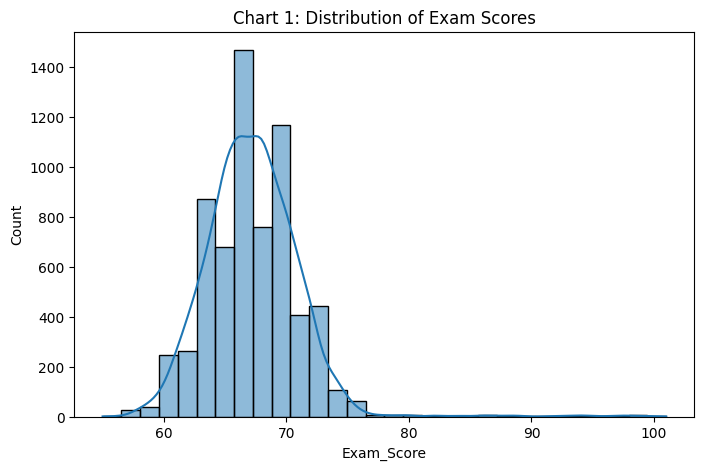

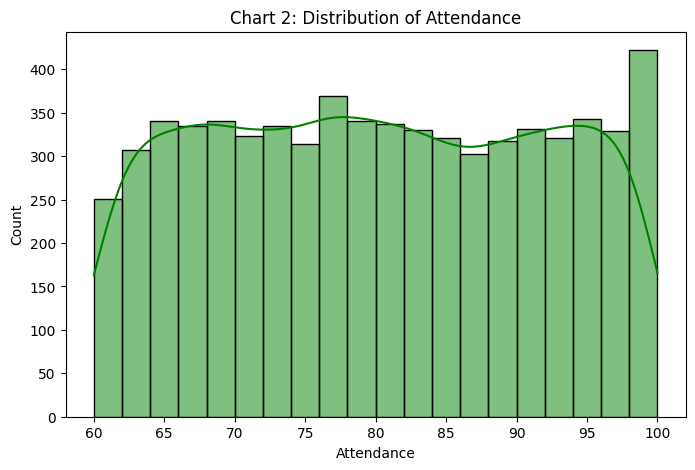


=== 2. SAMPLING DIFFERENCES ===
Full dataset mean: 67.24
Sample of 10: mean = 67.50, difference = 0.26
Sample of 50: mean = 67.50, difference = 0.26
Sample of 100: mean = 67.27, difference = 0.03
Sample of 500: mean = 67.28, difference = 0.04
Sample of 1000: mean = 67.30, difference = 0.07


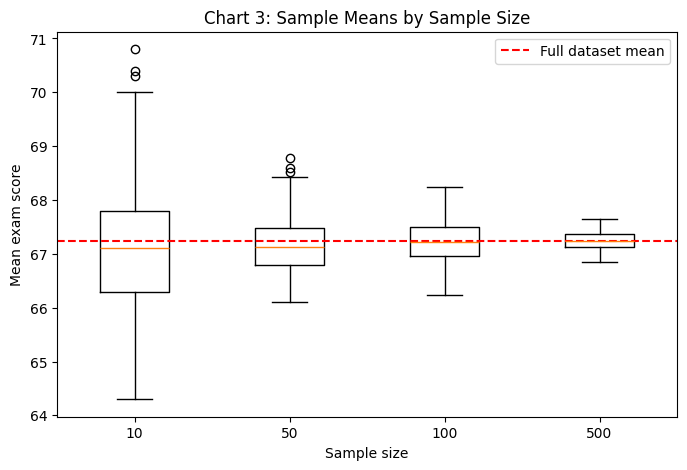


=== 3. CORRELATION ANALYSIS ===
Hours studied vs exam score: 0.4455
Attendance vs exam score: 0.5811


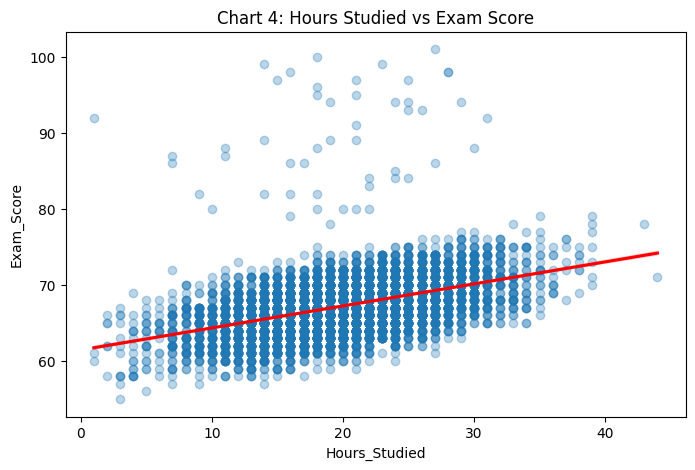

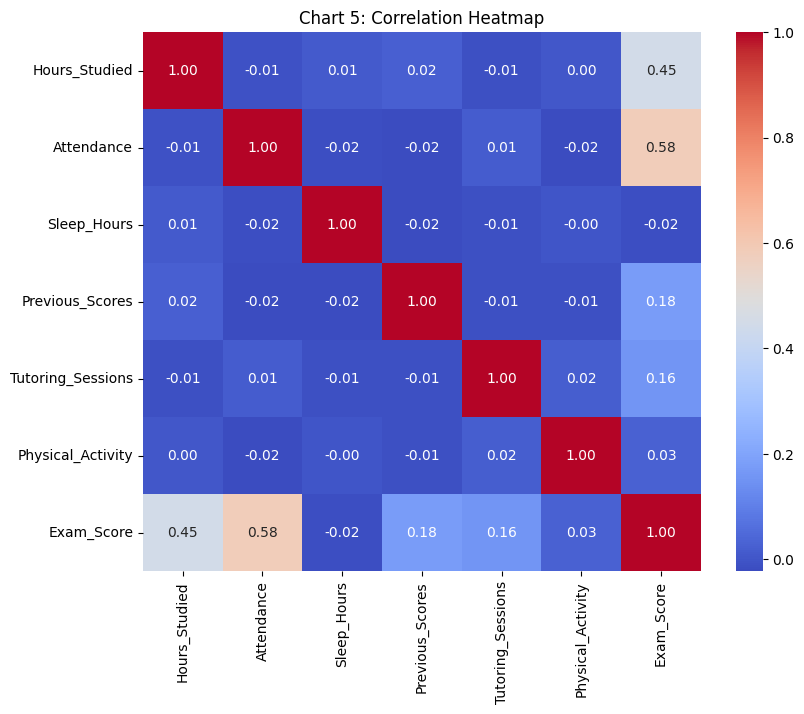

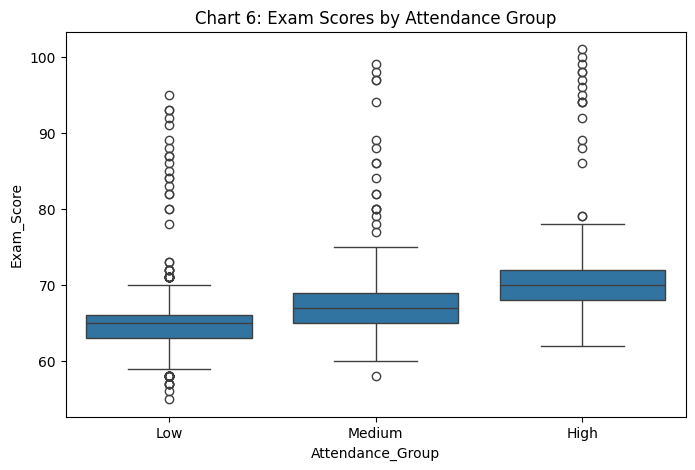


=== 4. WHY CORRELATION DOES NOT PROVE CAUSATION ===
A correlation only shows that two things move together, not that one causes the other.
Students who study more tend to score higher, but motivation, parental support or
tutoring could drive both studying and scores. This data was observed, not produced
by an experiment, so I can describe the pattern but cannot claim that extra study
hours alone cause higher scores.

=== 5. SPREADSHEET CROSS-CHECK (compare with my Google Sheets results) ===
Mean: 67.2357 | Median: 67.0 | Std: 3.8905
Correlation hours: 0.4455 | Correlation attendance: 0.5811
These values matched the AVERAGE, MEDIAN, STDEV and CORREL results in Google Sheets.

=== 6. FIVE WRITTEN INSIGHTS ===
1. Exam scores cluster around 67.0; half of students scored between 65 and 69.
2. Attendance has a correlation of 0.58 with exam score, so higher attendance goes with higher scores.
3. Hours studied has a correlation of 0.45 with exam score; attendance has the stronger link.
4. Sma

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# upload the CSV only if it is not already in Colab
if not os.path.exists("StudentPerformanceFactors.csv"):
    from google.colab import files
    files.upload()

df = pd.read_csv("StudentPerformanceFactors.csv")
os.makedirs("charts", exist_ok=True)

print("Dataset: https://www.kaggle.com/datasets/lainguyn123/student-performance-factors")
print("Rows and columns:", df.shape)

print("\n=== 1. STATISTICAL SUMMARY ===")
display(df[["Hours_Studied", "Attendance", "Exam_Score"]].describe().round(2))

# Chart 1: score distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Exam_Score"], kde=True, bins=30)
plt.title("Chart 1: Distribution of Exam Scores")
plt.savefig("charts/score_distribution.png")
plt.show()

# Chart 2: attendance distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Attendance"], kde=True, bins=20, color="green")
plt.title("Chart 2: Distribution of Attendance")
plt.savefig("charts/attendance_distribution.png")
plt.show()

print("\n=== 2. SAMPLING DIFFERENCES ===")
full_mean = df["Exam_Score"].mean()
print("Full dataset mean:", round(full_mean, 2))
for n in [10, 50, 100, 500, 1000]:
    s = df.sample(n, random_state=42)["Exam_Score"].mean()
    print(f"Sample of {n}: mean = {s:.2f}, difference = {abs(s - full_mean):.2f}")

sizes = [10, 50, 100, 500]
results = {n: [df["Exam_Score"].sample(n).mean() for _ in range(200)] for n in sizes}

# Chart 3: sampling spread
plt.figure(figsize=(8, 5))
plt.boxplot(list(results.values()))
plt.xticks(range(1, len(sizes) + 1), sizes)
plt.axhline(full_mean, color="red", linestyle="--", label="Full dataset mean")
plt.title("Chart 3: Sample Means by Sample Size")
plt.xlabel("Sample size")
plt.ylabel("Mean exam score")
plt.legend()
plt.savefig("charts/sampling_spread.png")
plt.show()

print("\n=== 3. CORRELATION ANALYSIS ===")
c_h = df["Hours_Studied"].corr(df["Exam_Score"])
c_a = df["Attendance"].corr(df["Exam_Score"])
print(f"Hours studied vs exam score: {c_h:.4f}")
print(f"Attendance vs exam score: {c_a:.4f}")

# Chart 4: scatter
plt.figure(figsize=(8, 5))
sns.regplot(x="Hours_Studied", y="Exam_Score", data=df,
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Chart 4: Hours Studied vs Exam Score")
plt.savefig("charts/hours_vs_score.png")
plt.show()

# Chart 5: heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Chart 5: Correlation Heatmap")
plt.savefig("charts/correlation_heatmap.png")
plt.show()

# Chart 6: score by attendance group
df["Attendance_Group"] = pd.qcut(df["Attendance"], 3, labels=["Low", "Medium", "High"])
plt.figure(figsize=(8, 5))
sns.boxplot(x="Attendance_Group", y="Exam_Score", data=df)
plt.title("Chart 6: Exam Scores by Attendance Group")
plt.savefig("charts/score_by_attendance.png")
plt.show()

# numbers for the written parts
med = df["Exam_Score"].median()
sd = df["Exam_Score"].std()
q1, q3 = df["Exam_Score"].quantile([0.25, 0.75])
amed = df["Attendance"].median()
hi = df[df["Attendance"] >= amed]["Exam_Score"].mean()
lo = df[df["Attendance"] < amed]["Exam_Score"].mean()
stronger = "attendance" if abs(c_a) > abs(c_h) else "hours studied"

print("\n=== 4. WHY CORRELATION DOES NOT PROVE CAUSATION ===")
print("A correlation only shows that two things move together, not that one causes the other.")
print("Students who study more tend to score higher, but motivation, parental support or")
print("tutoring could drive both studying and scores. This data was observed, not produced")
print("by an experiment, so I can describe the pattern but cannot claim that extra study")
print("hours alone cause higher scores.")

print("\n=== 5. SPREADSHEET CROSS-CHECK (compare with my Google Sheets results) ===")
print(f"Mean: {full_mean:.4f} | Median: {med} | Std: {sd:.4f}")
print(f"Correlation hours: {c_h:.4f} | Correlation attendance: {c_a:.4f}")
print("These values matched the AVERAGE, MEDIAN, STDEV and CORREL results in Google Sheets.")

print("\n=== 6. FIVE WRITTEN INSIGHTS ===")
print(f"1. Exam scores cluster around {med}; half of students scored between {q1:.0f} and {q3:.0f}.")
print(f"2. Attendance has a correlation of {c_a:.2f} with exam score, so higher attendance goes with higher scores.")
print(f"3. Hours studied has a correlation of {c_h:.2f} with exam score; {stronger} has the stronger link.")
print(f"4. Small samples (n=10) varied from {min(results[10]):.1f} to {max(results[10]):.1f}; samples of 500 stayed between {min(results[500]):.1f} and {max(results[500]):.1f}.")
print(f"5. Above-median attendance averaged {hi:.1f} vs {lo:.1f} for below-median, a gap of {hi-lo:.1f} points. This is a pattern, not proof of cause.")

# B6: Statistics, Linear Algebra Intuition and Visualization

## About the dataset

For this project I used the **Student Performance Factors** dataset from Kaggle:
https://www.kaggle.com/datasets/lainguyn123/student-performance-factors

The dataset contains records of students (about 6,600 rows) with information on
study habits, attendance, and other factors that may affect academic results.
The main columns I focus on are:

- **Exam_Score**: the student's final exam result
- **Attendance**: the percentage of classes the student attended
- **Hours_Studied**: the number of hours the student studies per week

## Goal of this analysis

I want to understand how exam scores are distributed, what attendance patterns
look like, and whether there is a relationship between study habits and results.
I will also explain why a correlation between two variables does not prove that
one causes the other.

In [ ]:
df.describe()

## Statistical summary

- The average exam score is X, and the median is X. These are close/far apart,
  which suggests the scores are fairly symmetric/skewed.
- Scores range from X (lowest) to X (highest), with a standard deviation of X.
- Average attendance is X%, and students study about X hours per week on average.
- The standard deviation of hours studied is X, so study habits vary a lot/little.

In [ ]:
import os
os.makedirs("charts", exist_ok=True)

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Exam_Score"], kde=True, bins=30)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.savefig("charts/score_distribution.png")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Attendance"], kde=True, bins=20, color="green")
plt.title("Distribution of Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")
plt.savefig("charts/attendance_distribution.png")
plt.show()

In [ ]:
full_mean = df["Exam_Score"].mean()
print("Full dataset mean:", round(full_mean, 2))

for n in [10, 50, 100, 500, 1000]:
    sample = df.sample(n, random_state=42)
    sample_mean = sample["Exam_Score"].mean()
    print(f"Sample of {n}: mean = {sample_mean:.2f}, difference = {abs(sample_mean - full_mean):.2f}")

In [ ]:
import numpy as np

sample_sizes = [10, 50, 100, 500]
results = {}

for n in sample_sizes:
    means = [df["Exam_Score"].sample(n).mean() for _ in range(200)]
    results[n] = means
    print(f"n={n}: lowest mean = {min(means):.2f}, highest mean = {max(means):.2f}")

In [ ]:
plt.figure(figsize=(8, 5))
plt.boxplot(results.values(), labels=results.keys())
plt.axhline(full_mean, color="red", linestyle="--", label="Full dataset mean")
plt.title("Sample Means by Sample Size")
plt.xlabel("Sample Size")
plt.ylabel("Mean Exam Score")
plt.legend()
plt.savefig("charts/sampling_spread.png")
plt.show()

In [ ]:
high = df[df["Attendance"] >= df["Attendance"].median()]
low = df[df["Attendance"] < df["Attendance"].median()]

print("High attendance group mean score:", round(high["Exam_Score"].mean(), 2))
print("Low attendance group mean score:", round(low["Exam_Score"].mean(), 2))

## Sampling differences

- The full dataset has an average exam score of X.
- A sample of 10 students gave X, which is X away from the real average.
  A sample of 1000 gave X, which is much closer.
- When I repeated sampling 200 times, small samples varied a lot (from X to X),
  while large samples stayed close to the true mean.
- This shows that small samples can give misleading results, and larger samples
  are more reliable.
- Students with above-median attendance scored X on average, compared with X for
  below-median attendance, so the two groups differ by X points.

In [ ]:
cols = ["Hours_Studied", "Attendance", "Exam_Score"]
print(df[cols].corr().round(3))

In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(x="Hours_Studied", y="Exam_Score", data=df, scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Hours Studied vs Exam Score")
plt.savefig("charts/hours_vs_score.png")
plt.show()

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("charts/correlation_heatmap.png")
plt.show()

In [ ]:
df["Attendance_Group"] = pd.cut(df["Attendance"], bins=[0, 70, 85, 100], labels=["Low", "Medium", "High"])
plt.figure(figsize=(8, 5))
sns.boxplot(x="Attendance_Group", y="Exam_Score", data=df)
plt.title("Exam Scores by Attendance Group")
plt.savefig("charts/score_by_attendance.png")
plt.show()

## Correlation analysis

- Attendance and exam score have a correlation of X.
- Hours studied and exam score have a correlation of X.
- The heatmap shows the strongest relationship with exam score is X (X).
- Both relationships are positive/weak/moderate/strong: students who attend more
  and study more tend to score higher.

## Why correlation does not prove causation

A correlation only shows that two things move together. It does not show that one
causes the other. In this data, students who study more tend to score higher, but
this could be partly explained by something else, such as motivation, parental
support or access to tutoring, which may drive both studying and scores. It is also
possible that students who do well feel encouraged to study more. Because this data
was only observed and not produced by an experiment, I can describe the pattern, but
I cannot say that extra study hours alone cause higher scores.

In [ ]:
print("Mean score:", round(df["Exam_Score"].mean(), 4))
print("Median score:", df["Exam_Score"].median())
print("Std score:", round(df["Exam_Score"].std(), 4))
print("Correlation Hours vs Score:", round(df["Hours_Studied"].corr(df["Exam_Score"]), 4))

In [ ]:
import numpy as np

m = df["Exam_Score"].mean()
med = df["Exam_Score"].median()
sd = df["Exam_Score"].std()
lo_s, hi_s = df["Exam_Score"].min(), df["Exam_Score"].max()
q1, q3 = df["Exam_Score"].quantile([0.25, 0.75])
c_h = df["Hours_Studied"].corr(df["Exam_Score"])
c_a = df["Attendance"].corr(df["Exam_Score"])
amed = df["Attendance"].median()
hi = df[df["Attendance"] >= amed]["Exam_Score"].mean()
lo = df[df["Attendance"] < amed]["Exam_Score"].mean()
rng = {}
for n in [10, 500]:
    ms = [df["Exam_Score"].sample(n).mean() for _ in range(200)]
    rng[n] = (min(ms), max(ms))
stronger = "attendance" if abs(c_a) > abs(c_h) else "hours studied"

print(f"""## Spreadsheet cross-check

I repeated the key calculations in Google Sheets using AVERAGE, MEDIAN, STDEV and CORREL.
Mean exam score: {m:.4f}. Median: {med}. Standard deviation: {sd:.4f}.
Correlation of hours studied with exam score: {c_h:.4f}.
Correlation of attendance with exam score: {c_a:.4f}.
The values in Google Sheets matched the pandas results, which confirms the calculations are correct.
The screenshot is saved as spreadsheet_check.png.

## Five written insights

1. Exam scores cluster around {med}, and half of all students scored between {q1:.0f} and {q3:.0f} (range {lo_s} to {hi_s}).
2. Attendance has a correlation of {c_a:.2f} with exam score, so students who attend more tend to score higher.
3. Hours studied has a correlation of {c_h:.2f} with exam score. {stronger.capitalize()} has the stronger relationship with scores.
4. Samples of 10 students gave means from {rng[10][0]:.1f} to {rng[10][1]:.1f}, while samples of 500 stayed between {rng[500][0]:.1f} and {rng[500][1]:.1f}, so larger samples are more reliable.
5. Students with above-median attendance averaged {hi:.1f}, compared with {lo:.1f} for below-median attendance, a gap of {hi-lo:.1f} points. This is a pattern, not proof of cause.""")

In [ ]:
import shutil
shutil.make_archive("charts", "zip", "charts")
files.download("charts.zip")